# Data Preprocessing: Healthcare Stroke Dataset
Notebook ini memuat tahap pra-pemrosesan data (*Data Understanding & Preprocessing*) untuk dataset rekam medis pasien stroke (*Stroke Prediction Dataset*).

* **Dataset Asal:** `healthcare_dataset_stroke_data.csv` (5.110 data pasien)
* **Karakteristik Data:** 5.110 baris rekam medis dan 12 atribut klinis serta demografis.
* **Fokus Analisis:**
  1. Pemeriksaan Dimensi Data (Jumlah Record & Atribut)
  2. Analisis Nilai Kosong (*Missing Value*) & Visualisasi Heatmap
  3. Pemeriksaan Data Duplikat & Pasien Unik
  4. Analisis Distribusi Kasus Stroke (Variabel Target)
  5. Deteksi Data Pencilan (*Outlier*) pada Atribut Klinis (Kadar Gula Darah & BMI) menggunakan Metode IQR dan Boxplot


### 1. Import Library
Memanggil library data science (pandas, numpy, matplotlib, seaborn).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### 2. Membaca Dataset
Memuat file CSV dataset rekam medis kesehatan pasien ke dalam DataFrame pandas.


In [2]:
df = pd.read_csv('healthcare_dataset_stroke_data.csv')


### 3. Menampilkan 5 Data Teratas (Head)
Melihat sampel 5 baris pertama data pasien.


In [3]:
df.head()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### 4. Menampilkan 5 Data Terbawah (Tail)
Melihat sampel 5 baris terakhir data pasien.


In [4]:
df.tail()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


### 5. Jumlah Baris (Record)
Menghitung total baris data pasien pada dataset.


In [5]:
print("Jumlah Baris:", len(df))


Jumlah Baris: 5110


### 6. Jumlah Kolom (Atribut)
Menghitung total kolom atribut pada dataset.


In [6]:
print("Jumlah Kolom:", len(df.columns))


Jumlah Kolom: 12


### 7. Cek Tipe Data & Struktur DataFrame
Memeriksa informasi tipe data setiap kolom dan ringkasan penggunaan memori.


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


### 8. Cek Missing Value per Kolom
Menghitung jumlah nilai kosong (NaN/null) pada masing-masing kolom atribut.


In [8]:
df.isnull().sum().to_frame(name='Jumlah Missing Value')


,Jumlah Missing Value
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


### 9. Total Missing Value Keseluruhan
Menghitung total seluruh nilai kosong pada dataset.


In [9]:
print("Total Missing Value Keseluruhan:", df.isnull().sum().sum())


Total Missing Value Keseluruhan: 201


### 10. Persentase Missing Value
Menghitung rasio persentase data kosong terhadap total sel data.


In [10]:
total_sel = len(df) * len(df.columns)
persen_missing = (df.isnull().sum().sum() / total_sel) * 100
print(f"Persentase Missing Value: {persen_missing:.2f}%")


Persentase Missing Value: 0.33%


### 11. Visualisasi Heatmap Missing Value (Sebelum Penanggulangan)
Menampilkan peta sebaran nilai kosong pada seluruh baris data pasien sebelum dilakukan imputasi klinis.


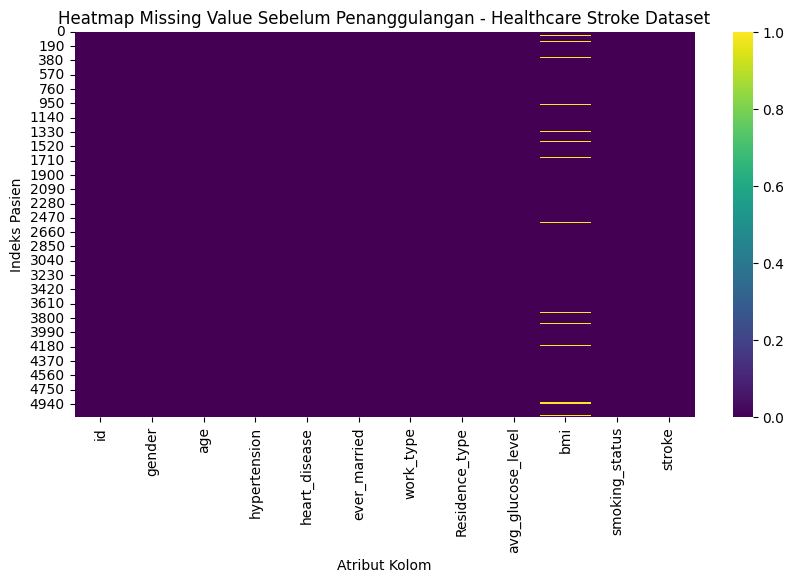

In [11]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap Missing Value Sebelum Penanggulangan - Healthcare Stroke Dataset')
plt.xlabel('Atribut Kolom')
plt.ylabel('Indeks Pasien')
plt.show()


### 12. Penanggulangan Missing Value (Imputasi Median BMI)
Mengatasi nilai kosong pada parameter klinis BMI menggunakan teknik Imputasi Median.


In [12]:
median_bmi = df['bmi'].median()
df['bmi'] = df['bmi'].fillna(median_bmi)

print(f"Nilai Median BMI yang Digunakan: {median_bmi:.2f}")
print("Total Missing Value Setelah Penanggulangan:", df.isnull().sum().sum())


Nilai Median BMI yang Digunakan: 28.10
Total Missing Value Setelah Penanggulangan: 0


### 13. Visualisasi Heatmap Missing Value Pasca Penanggulangan
Menampilkan kembali visualisasi Heatmap untuk membuktikan bahwa dataset rekam medis telah bebas 100% dari data kosong.


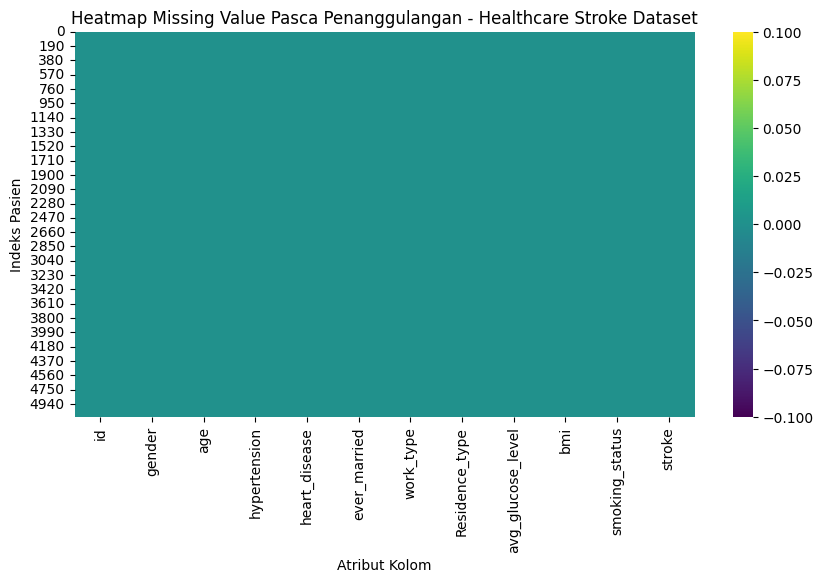

In [13]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap Missing Value Pasca Penanggulangan - Healthcare Stroke Dataset')
plt.xlabel('Atribut Kolom')
plt.ylabel('Indeks Pasien')
plt.show()


### 14. Cek Jumlah Duplikat Data
Memeriksa apakah terdapat baris duplikat penuh pada data pasien.



In [14]:
jumlah_duplikat = df.duplicated().sum()
print("Jumlah Baris Duplikat:", jumlah_duplikat)


Jumlah Baris Duplikat: 0


### 15. Cek Jumlah Pasien Unik
Menghitung total nomor rekam medis / ID pasien unik (id).



In [15]:
print("Jumlah Pasien Unik:", df['id'].nunique())


Jumlah Pasien Unik: 5110


### 16. Distribusi Kasus Stroke (Variabel Target)
Melihat sebaran frekuensi dan persentase pasien yang mengalami stroke vs tidak stroke.



In [16]:
distribusi_stroke = df['stroke'].value_counts().to_frame(name='Jumlah Pasien')
distribusi_stroke['Persentase (%)'] = (distribusi_stroke['Jumlah Pasien'] / len(df) * 100).round(2)
display(distribusi_stroke)


,Jumlah Pasien,Persentase (%)
stroke,,
0,4861,95.13
1,249,4.87


### 17. Pemilihan Atribut Numerik untuk Analisis Outlier
Memilih kolom klinis berskala numerik kontinu (Usia, Kadar Gula Darah, dan BMI).



In [17]:
kolom_numerik = ['age', 'avg_glucose_level', 'bmi']
df_numerik = df[kolom_numerik]


### 18. Statistik Deskriptif Atribut Numerik Klinis
Melihat nilai rata-rata, standar deviasi, nilai minimum, dan maksimum parameter medis pasien.



In [18]:
df_numerik.describe()


,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,5110.000000
mean,43.226614,106.147677,28.862035
std,22.612647,45.283560,7.699562
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.800000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,32.800000
max,82.000000,271.740000,97.600000


### 19. Visualisasi Boxplot Deteksi Outlier Numerik
Menampilkan diagram kotak garis (Boxplot) untuk menganalisis sebaran dan potensi pencilan klinis.



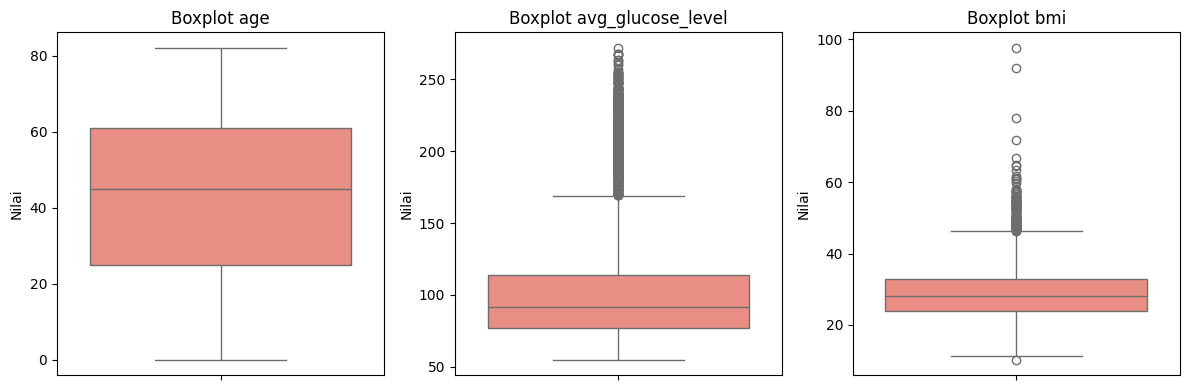

In [19]:
plt.figure(figsize=(12, 4))
for i, col in enumerate(kolom_numerik, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col], color='salmon')
    plt.title(f'Boxplot {col}')
    plt.ylabel('Nilai')
plt.tight_layout()
plt.show()


### 20. Perhitungan Kuartil (Q1, Q3) dan IQR Kadar Gula Darah
Menghitung kuartil bawah (25%), kuartil atas (75%), dan rentang antarkuartil atribut avg_glucose_level.



In [20]:
gula = df['avg_glucose_level']
Q1 = gula.quantile(0.25)
Q3 = gula.quantile(0.75)
IQR = Q3 - Q1
print(f"Q1 (Kuartil Bawah) : {Q1:.2f}")
print(f"Q3 (Kuartil Atas)  : {Q3:.2f}")
print(f"IQR               : {IQR:.2f}")


Q1 (Kuartil Bawah) : 77.25
Q3 (Kuartil Atas)  : 114.09
IQR               : 36.84


### 21. Perhitungan Batas Atas Outlier Kadar Gula Darah
Menghitung ambang batas atas deteksi outlier menggunakan rumus Q3 + (1.5 * IQR).



In [21]:
batas_atas = Q3 + 1.5 * IQR
print(f"Batas Atas Outlier Gula Darah: {batas_atas:.2f}")


Batas Atas Outlier Gula Darah: 169.36


### 22. Jumlah Pasien Terdeteksi Outlier Kadar Gula Darah
Menghitung total pasien dengan kadar gula darah melebihi batas atas IQR.



In [22]:
outliers_gula = df[df['avg_glucose_level'] > batas_atas]
print("Jumlah Pasien Outlier Gula Darah:", len(outliers_gula))


Jumlah Pasien Outlier Gula Darah: 627


### 23. Daftar 10 Pasien dengan Kadar Gula Darah Tertinggi
Menampilkan 10 data pasien pencilan dengan kadar gula darah tertinggi.



In [23]:
outliers_gula[['id', 'gender', 'age', 'hypertension', 'avg_glucose_level', 'bmi', 'stroke']].sort_values(by='avg_glucose_level', ascending=False).head(10)


,id,gender,age,hypertension,avg_glucose_level,bmi,stroke
193,69112,Male,68.0,1,271.74,31.1,1
1207,22440,Female,49.0,0,267.76,29.3,0
3088,26267,Female,76.0,0,267.61,27.9,0
4983,10995,Male,76.0,1,267.60,30.5,0
2462,27626,Female,60.0,0,266.59,25.5,0
3393,13155,Female,67.0,1,263.56,26.3,0
135,71279,Female,71.0,0,263.32,38.7,1
4457,50070,Female,62.0,1,261.67,43.0,0
3215,21534,Male,67.0,0,260.85,28.1,0
122,13491,Male,80.0,0,259.63,31.7,1
